In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [2]:
df = pd.read_csv("../data/raw/hakhathon_data.csv")

print("Данные успешно загружены!")

Данные успешно загружены!


In [3]:
print("Количество строк и столбцов:", df.shape)

Количество строк и столбцов: (180901, 12)


In [4]:
display(df.head(10))

,ID,Time,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor
0,1,06.05.2026 11:00:00,3226.47998,17.859133,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025953,0.201727
1,2,06.05.2026 11:00:05,3226.47998,17.856710,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025965,0.195013
2,3,06.05.2026 11:00:10,3226.47998,17.886156,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025909,0.200235
3,4,06.05.2026 11:00:15,3226.47998,17.860680,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025883,0.203219
4,5,06.05.2026 11:00:20,3226.47998,17.843225,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025903,0.210678
5,6,06.05.2026 11:00:25,3226.47998,17.854677,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025893,0.202473
6,7,06.05.2026 11:00:30,3226.47998,17.869967,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025790,0.208440
7,8,06.05.2026 11:00:35,3226.47998,17.868353,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025881,0.200981
8,9,06.05.2026 11:00:40,3226.47998,17.872437,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025846,0.207694
9,10,06.05.2026 11:00:45,3226.47998,17.864159,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025883,0.199489


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180901 entries, 0 to 180900
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ID                      180901 non-null  int64  
 1   Time                    180901 non-null  str    
 2   Depth                   180901 non-null  float64
 3   HL                      180901 non-null  float64
 4   TravelingBlockPosition  180901 non-null  float64
 5   ManifoldPressure        180901 non-null  float64
 6   ROP                     180901 non-null  float64
 7   InletFlow               180901 non-null  float64
 8   Load                    180901 non-null  float64
 9   BitPosition             180901 non-null  float64
 10  WedgePosition           180901 non-null  float64
 11  Turn_rotor              180901 non-null  float64
dtypes: float64(10), int64(1), str(1)
memory usage: 16.6 MB


In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,180901.0,90451.000000,52221.764861,1.000000,45226.000000,90451.000000,135676.000000,180901.000000
Depth,180901.0,3513.453919,155.006631,3226.479980,3401.418701,3610.932129,3610.932129,3610.932129
HL,180901.0,45.252230,27.464795,-6.407499,12.106071,53.876324,64.763702,115.313126
TravelingBlockPosition,180901.0,16.236663,8.579291,-3.753203,9.358555,16.171757,24.504921,51.965038
ManifoldPressure,180901.0,4.214434,6.327020,0.106380,0.220518,0.254740,8.091122,20.997688
ROP,180901.0,2.172153,4.507938,0.058164,0.832193,0.832193,0.832193,32.407967
InletFlow,180901.0,3.923847,5.797549,0.000000,0.000000,0.000000,10.908408,51.043442
Load,180901.0,5.125019,12.404777,0.000000,0.000000,0.419264,3.512410,58.736034
BitPosition,180901.0,867.393532,1313.486222,0.000000,11.713945,67.044182,1452.265381,3620.069824
WedgePosition,180901.0,0.620892,0.548538,-0.860561,-0.004163,1.000000,1.000000,2.222592


In [7]:
print("Полные дубликаты:", df.duplicated().sum())
print("Повторяющиеся ID:", df["ID"].duplicated().sum())
print("Повторяющиеся значения Time:", df["Time"].duplicated().sum())

Полные дубликаты: 0
Повторяющиеся ID: 0
Повторяющиеся значения Time: 2


In [8]:
df["Time"] = pd.to_datetime(
    df["Time"],
    format="%d.%m.%Y %H:%M:%S",
    errors="coerce"
)

print("Некорректных значений времени:", df["Time"].isna().sum())
print("Начало периода:", df["Time"].min())
print("Конец периода:", df["Time"].max())

Некорректных значений времени: 0
Начало периода: 2026-05-06 11:00:00
Конец периода: 2026-05-16 22:15:00


In [9]:
time_diff = df["Time"].diff().dt.total_seconds()

print("Интервалы между измерениями:")
display(time_diff.value_counts().head(10))

Интервалы между измерениями:


Time
5.0     166904
1.0      13501
4.0        172
6.0        152
2.0         34
3.0         30
8.0         25
10.0        24
9.0         20
7.0         19
Name: count, dtype: int64

In [10]:
duplicates = df[df["Time"].duplicated(keep=False)]

display(duplicates.sort_values("Time"))

,ID,Time,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor
40482,40483,2026-05-08 19:13:35,3331.215820,55.240536,10.603164,15.070091,1.055307,11.845580,2.280792,0.509336,1.103068,18.372576
40483,40484,2026-05-08 19:13:35,3331.215820,55.102673,10.603164,15.070091,1.055307,11.845580,2.280792,0.509336,1.104468,18.333416
103647,103648,2026-05-12 10:57:21,3610.932129,69.058258,4.949141,2.466810,0.832193,4.168285,0.164902,52.727459,1.000000,42.801777
103648,103649,2026-05-12 10:57:21,3610.932129,69.967972,5.480664,2.466810,0.832193,4.168285,0.164902,52.727459,1.000000,41.585911


In [11]:
print("Данные отсортированы по времени:", df["Time"].is_monotonic_increasing)

print("Нарушений порядка времени:", (df["Time"].diff().dt.total_seconds() < 0).sum())

Данные отсортированы по времени: True
Нарушений порядка времени: 0


In [12]:
df = df.sort_values("Time").reset_index(drop=True)

time_diff = df["Time"].diff().dt.total_seconds()

print("Распределение временных интервалов:")
display(time_diff.value_counts().sort_index().head(20))

print("Нулевые интервалы:", (time_diff == 0).sum())
print("Отрицательные интервалы:", (time_diff < 0).sum())
print("Интервалы больше 5 секунд:", (time_diff > 5).sum())

Распределение временных интервалов:


Time
0.0             2
1.0         13501
2.0            34
3.0            30
4.0           172
5.0        166904
6.0           152
7.0            19
8.0            25
9.0            20
10.0           24
11.0            9
12.0            2
16.0            1
18.0            1
21.0            1
477.0           1
1479.0          1
51834.0         1
Name: count, dtype: int64

Нулевые интервалы: 2
Отрицательные интервалы: 0
Интервалы больше 5 секунд: 257


In [13]:
gap_table = pd.DataFrame({
    "Previous_ID": df["ID"].shift(1),
    "Current_ID": df["ID"],
    "PreviousTime": df["Time"].shift(1),
    "CurrentTime": df["Time"],
    "GapSeconds": time_diff
})

gaps = gap_table[gap_table["GapSeconds"] > 5]

display(
    gaps.sort_values("GapSeconds", ascending=False).head(20)
)

,Previous_ID,Current_ID,PreviousTime,CurrentTime,GapSeconds
74011,74011.0,74012,2026-05-10 17:47:30,2026-05-11 08:11:24,51834.0
162486,162486.0,162487,2026-05-15 20:40:25,2026-05-15 21:05:04,1479.0
167365,167365.0,167366,2026-05-16 03:27:00,2026-05-16 03:34:57,477.0
809,809.0,810,2026-05-06 12:07:20,2026-05-06 12:07:41,21.0
125842,125842.0,125843,2026-05-13 17:46:45,2026-05-13 17:47:03,18.0
107204,107204.0,107205,2026-05-12 15:53:35,2026-05-12 15:53:51,16.0
40595,40595.0,40596,2026-05-08 19:22:50,2026-05-08 19:23:02,12.0
50352,50352.0,50353,2026-05-09 08:55:55,2026-05-09 08:56:07,12.0
111316,111316.0,111317,2026-05-12 21:36:15,2026-05-12 21:36:26,11.0
37001,37001.0,37002,2026-05-08 14:23:20,2026-05-08 14:23:31,11.0


In [14]:
print("Разрывы больше 10 секунд:", (time_diff > 10).sum())
print("Разрывы больше 1 минуты:", (time_diff > 60).sum())
print("Разрывы больше 5 минут:", (time_diff > 300).sum())
print("Разрывы больше 1 часа:", (time_diff > 3600).sum())

Разрывы больше 10 секунд: 17
Разрывы больше 1 минуты: 3
Разрывы больше 5 минут: 3
Разрывы больше 1 часа: 1


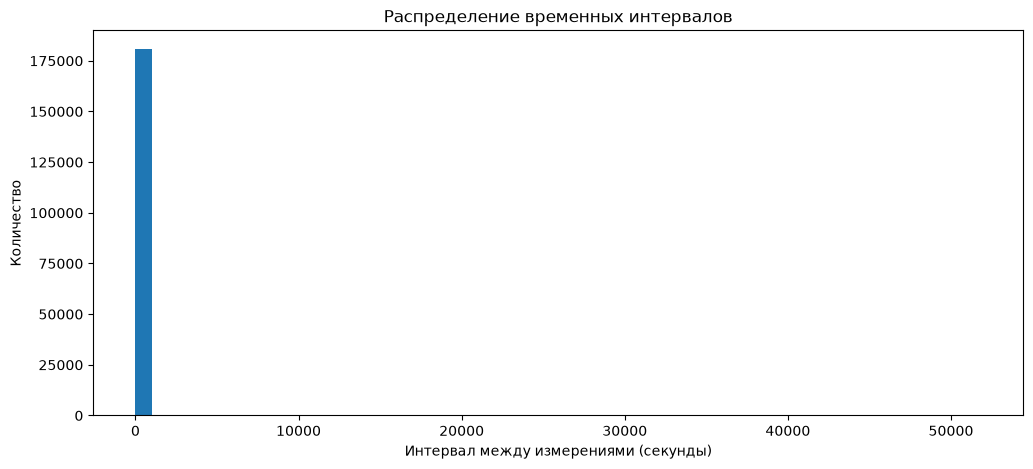

In [15]:
plt.figure(figsize=(12, 5))

plt.hist(time_diff.dropna(), bins=50)

plt.xlabel("Интервал между измерениями (секунды)")
plt.ylabel("Количество")
plt.title("Распределение временных интервалов")

plt.show()

In [16]:
gap_idx = time_diff.idxmax()

display(
    df.loc[gap_idx-3:gap_idx+3, [
        "ID", "Time", "Depth", "HL",
        "TravelingBlockPosition", "ManifoldPressure",
        "ROP", "InletFlow", "Load"
    ]]
)

,ID,Time,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load
74008,74009,2026-05-10 17:47:20,3610.932129,51.048367,14.808320,0.246427,0.832193,0.0,7.081577
74009,74010,2026-05-10 17:47:25,3610.932129,50.944614,14.287539,0.246427,0.832193,0.0,7.081577
74010,74011,2026-05-10 17:47:30,3610.932129,51.105228,14.287539,0.246427,0.832193,0.0,7.081577
74011,74012,2026-05-11 08:11:24,3610.932129,50.552811,9.688516,0.246427,0.832193,0.0,7.081577
74012,74013,2026-05-11 08:11:25,3610.932129,50.546234,9.688516,0.246427,0.832193,0.0,7.081577
74013,74014,2026-05-11 08:11:26,3610.932129,50.363983,9.688516,0.246427,0.832193,0.0,7.081577
74014,74015,2026-05-11 08:11:27,3610.932129,50.366028,9.688516,0.246427,0.832193,0.0,7.081577


In [17]:
print("Разрывы больше 10 секунд:", (time_diff > 10).sum())
print("Разрывы больше 1 минуты:", (time_diff > 60).sum())
print("Разрывы больше 5 минут:", (time_diff > 300).sum())
print("Разрывы больше 1 часа:", (time_diff > 3600).sum())

Разрывы больше 10 секунд: 17
Разрывы больше 1 минуты: 3
Разрывы больше 5 минут: 3
Разрывы больше 1 часа: 1


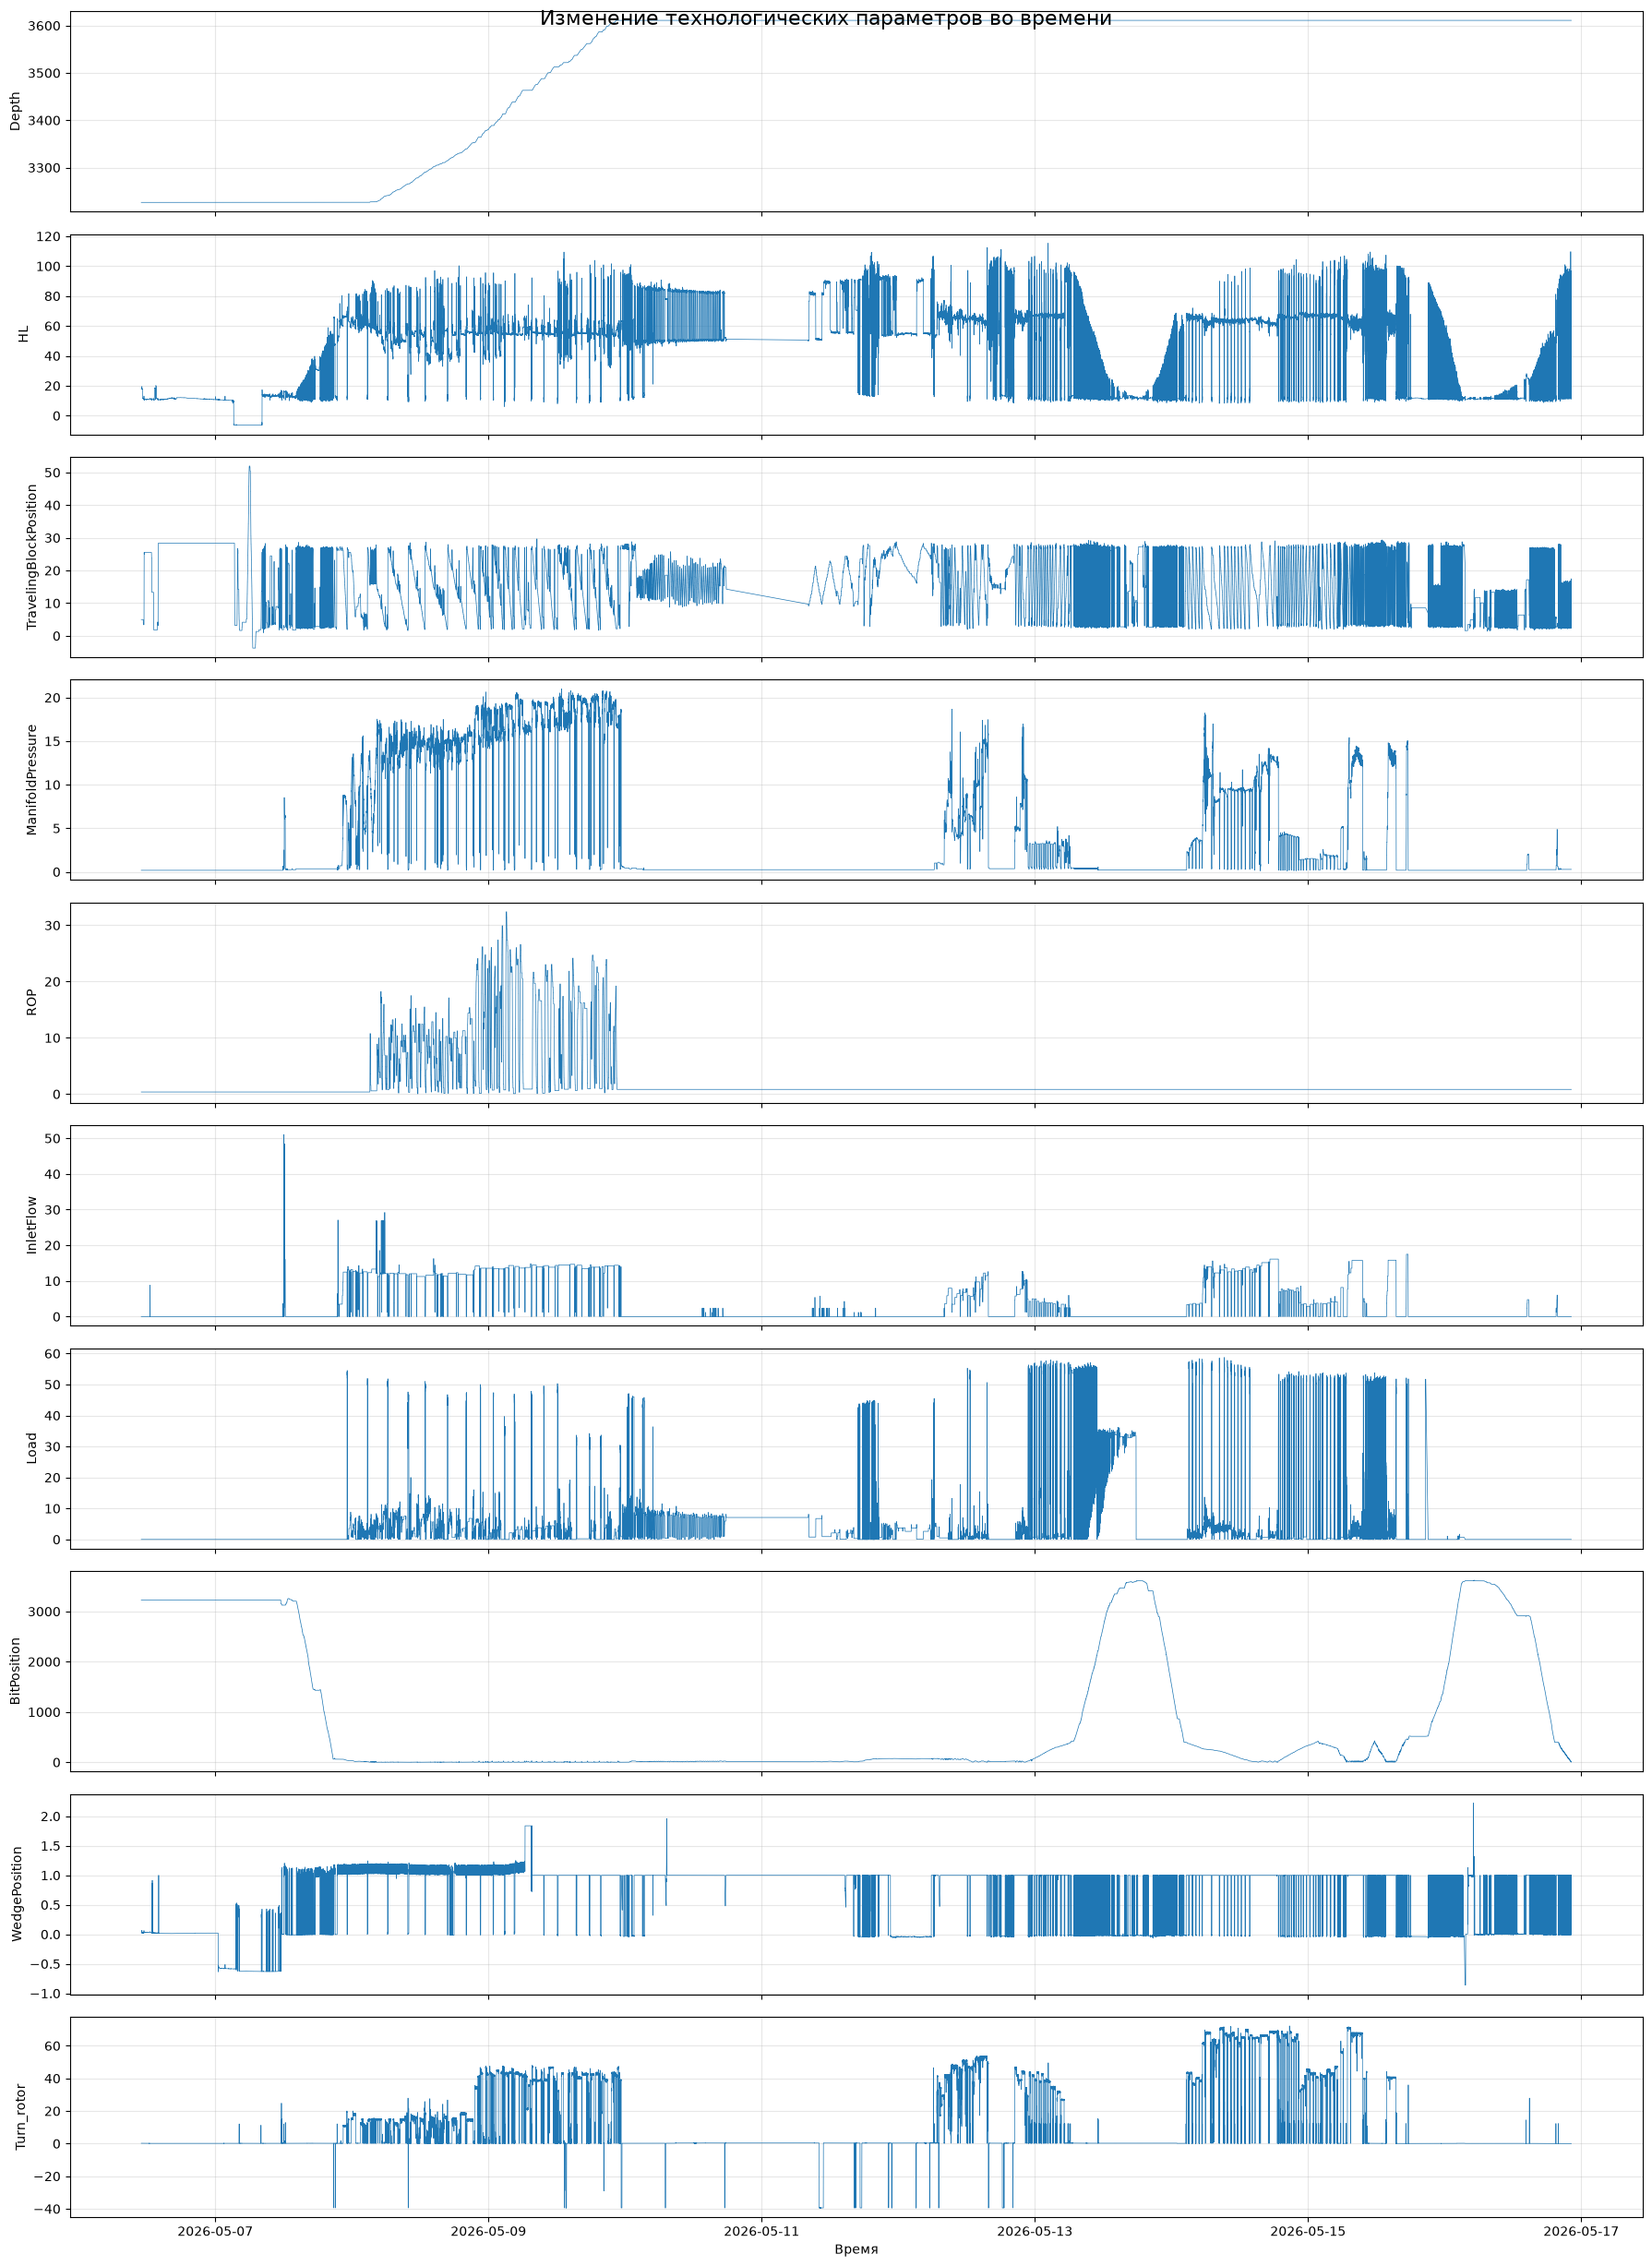

In [18]:
features = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor"
]

fig, axes = plt.subplots(
    len(features), 1,
    figsize=(18, 25),
    sharex=True
)

for ax, feature in zip(axes, features):
    ax.plot(df["Time"], df[feature], linewidth=0.5)
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Время")

fig.suptitle(
    "Изменение технологических параметров во времени",
    fontsize=16
)

plt.tight_layout()
plt.show()

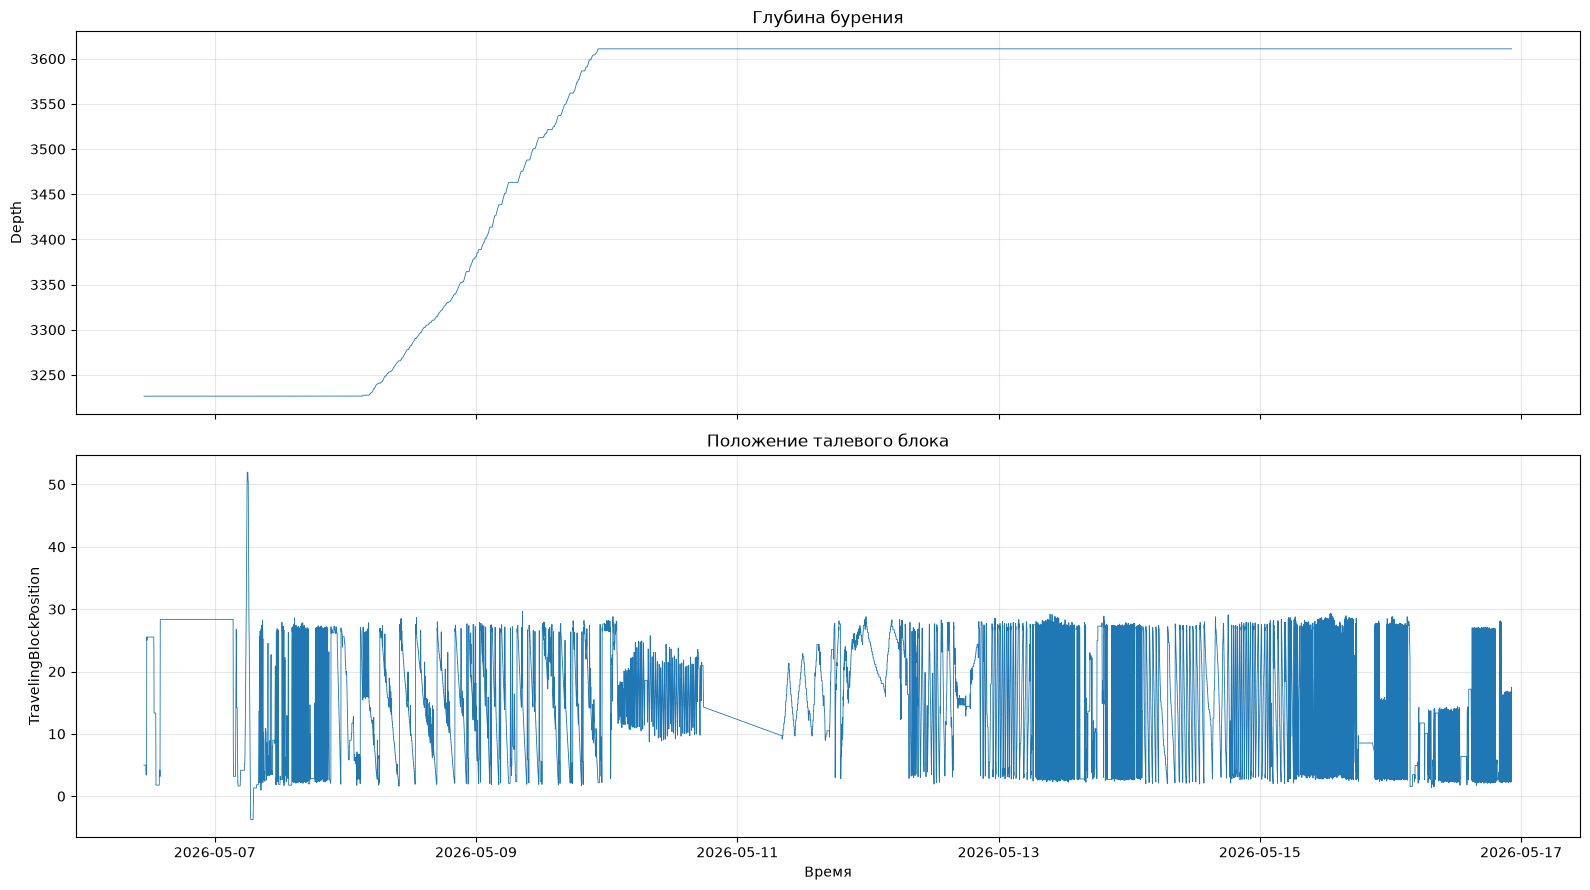

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

axes[0].plot(df["Time"], df["Depth"], linewidth=0.6)
axes[0].set_title("Глубина бурения")
axes[0].set_ylabel("Depth")
axes[0].grid(alpha=0.3)

axes[1].plot(
    df["Time"],
    df["TravelingBlockPosition"],
    linewidth=0.6
)
axes[1].set_title("Положение талевого блока")
axes[1].set_ylabel("TravelingBlockPosition")
axes[1].set_xlabel("Время")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

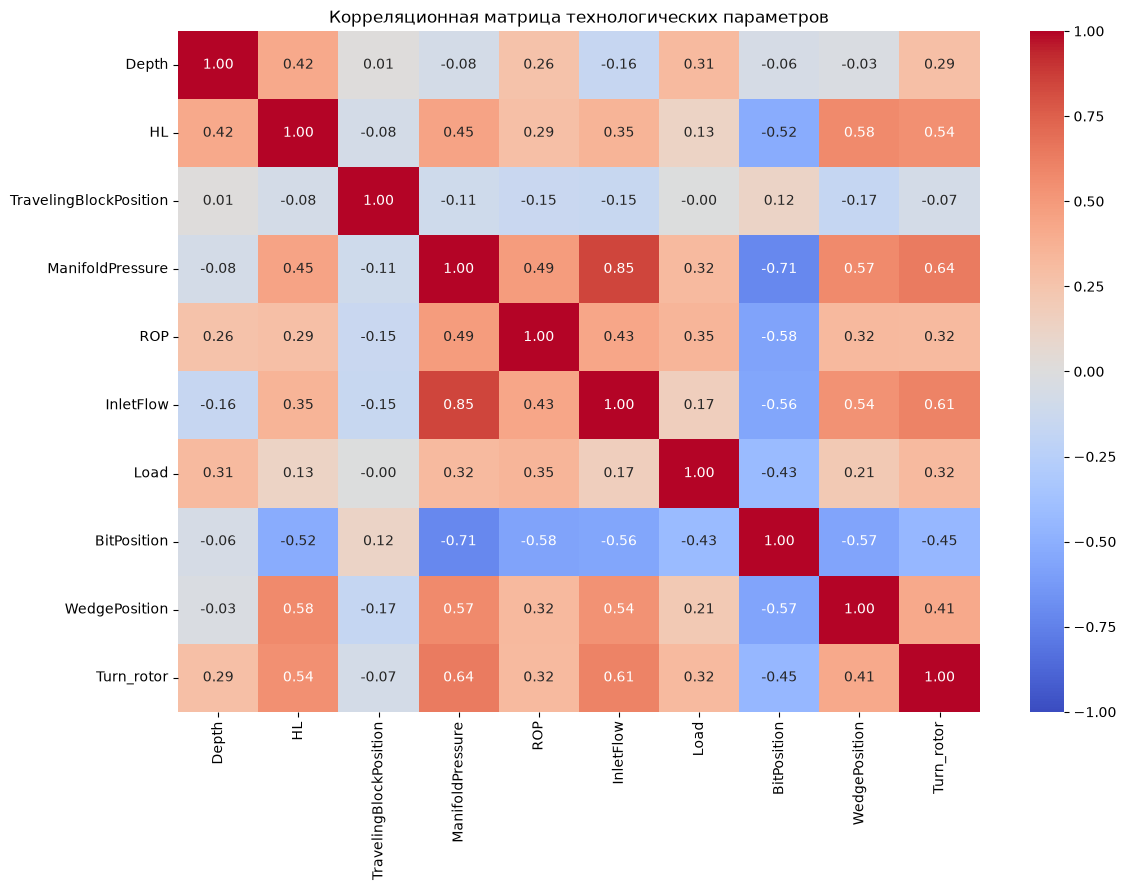

In [20]:
features = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor"
]

corr = df[features].corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица технологических параметров")
plt.tight_layout()
plt.show()

In [22]:
upper = np.triu_indices_from(corr, k=1)

corr_pairs = pd.DataFrame({
    "Feature_1": corr.columns[upper[0]],
    "Feature_2": corr.columns[upper[1]],
    "Correlation": corr.to_numpy()[upper]
})

display(
    corr_pairs.assign(
        AbsCorrelation=corr_pairs["Correlation"].abs()
    )
    .sort_values("AbsCorrelation", ascending=False)
    .drop(columns="AbsCorrelation")
    .reset_index(drop=True)
)

,Feature_1,Feature_2,Correlation
0,ManifoldPressure,InletFlow,0.847295
1,ManifoldPressure,BitPosition,-0.713017
2,ManifoldPressure,Turn_rotor,0.636931
3,InletFlow,Turn_rotor,0.605537
4,ROP,BitPosition,-0.577200
5,HL,WedgePosition,0.576536
6,ManifoldPressure,WedgePosition,0.571973
7,BitPosition,WedgePosition,-0.565375
8,InletFlow,BitPosition,-0.555299
9,HL,Turn_rotor,0.543335


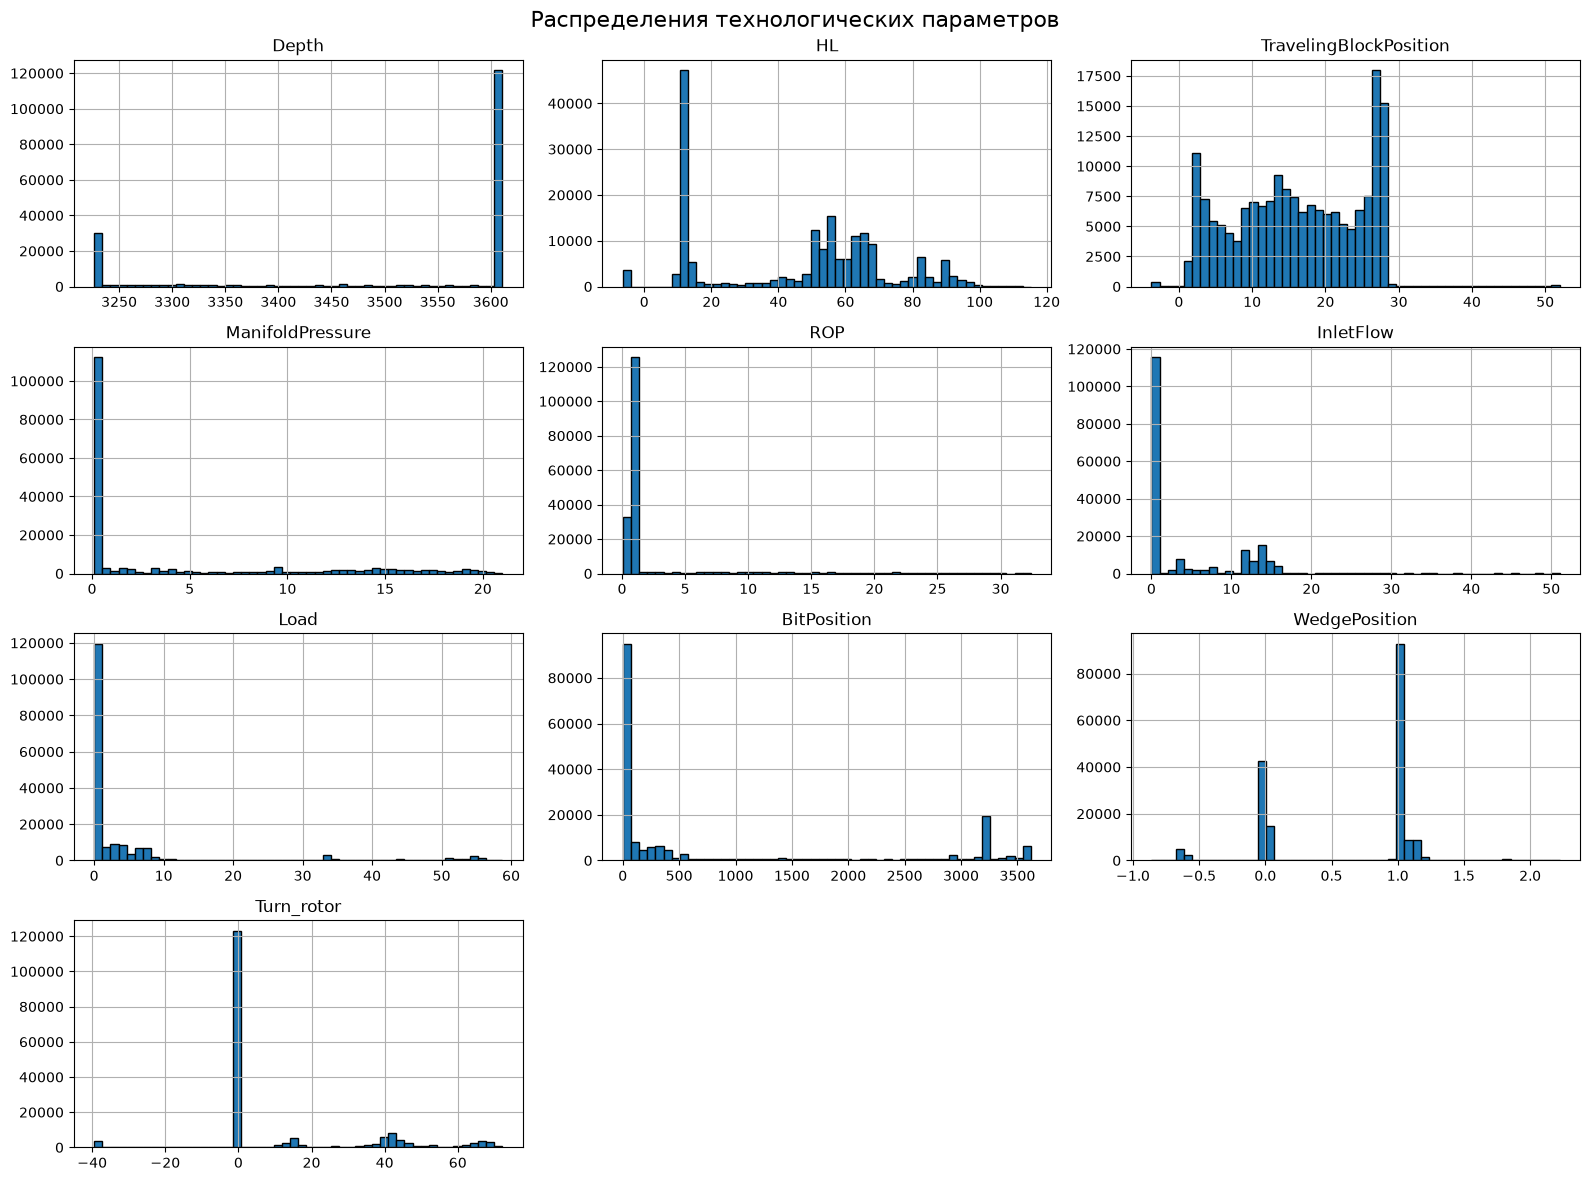

In [23]:
features = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor"
]

df[features].hist(
    figsize=(16, 12),
    bins=50,
    edgecolor="black"
)

plt.suptitle("Распределения технологических параметров", fontsize=16)
plt.tight_layout()
plt.show()

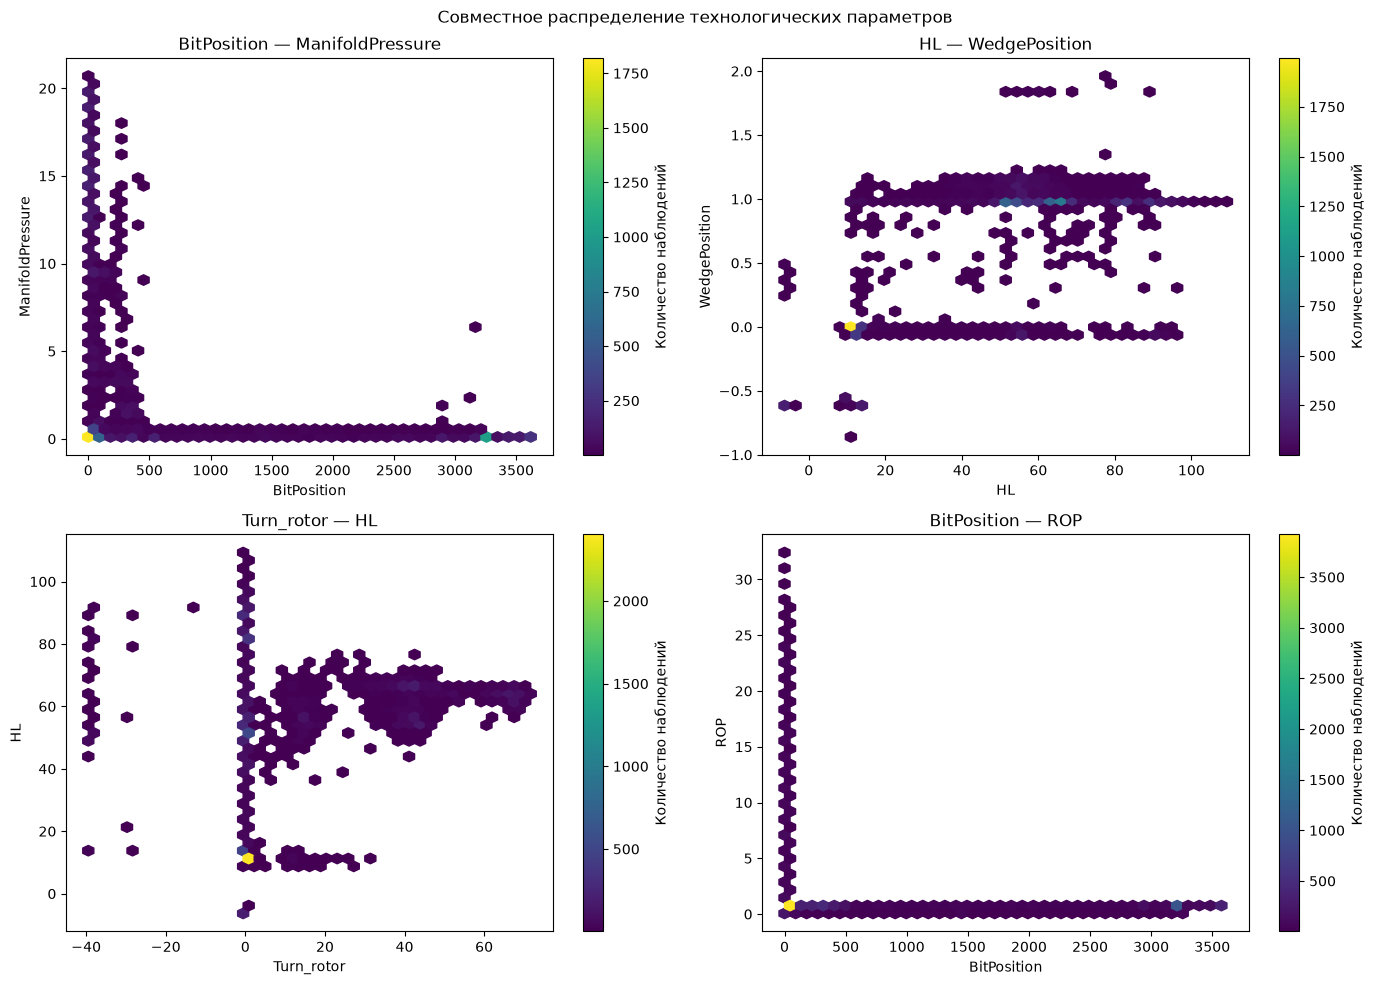

In [24]:
sample = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plots = [
    ("BitPosition", "ManifoldPressure"),
    ("HL", "WedgePosition"),
    ("Turn_rotor", "HL"),
    ("BitPosition", "ROP")
]

for ax, (x, y) in zip(axes.flat, plots):
    hb = ax.hexbin(
        sample[x],
        sample[y],
        gridsize=40,
        mincnt=1,
        cmap="viridis"
    )
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} — {y}")
    fig.colorbar(hb, ax=ax, label="Количество наблюдений")

plt.suptitle("Совместное распределение технологических параметров")
plt.tight_layout()
plt.show()

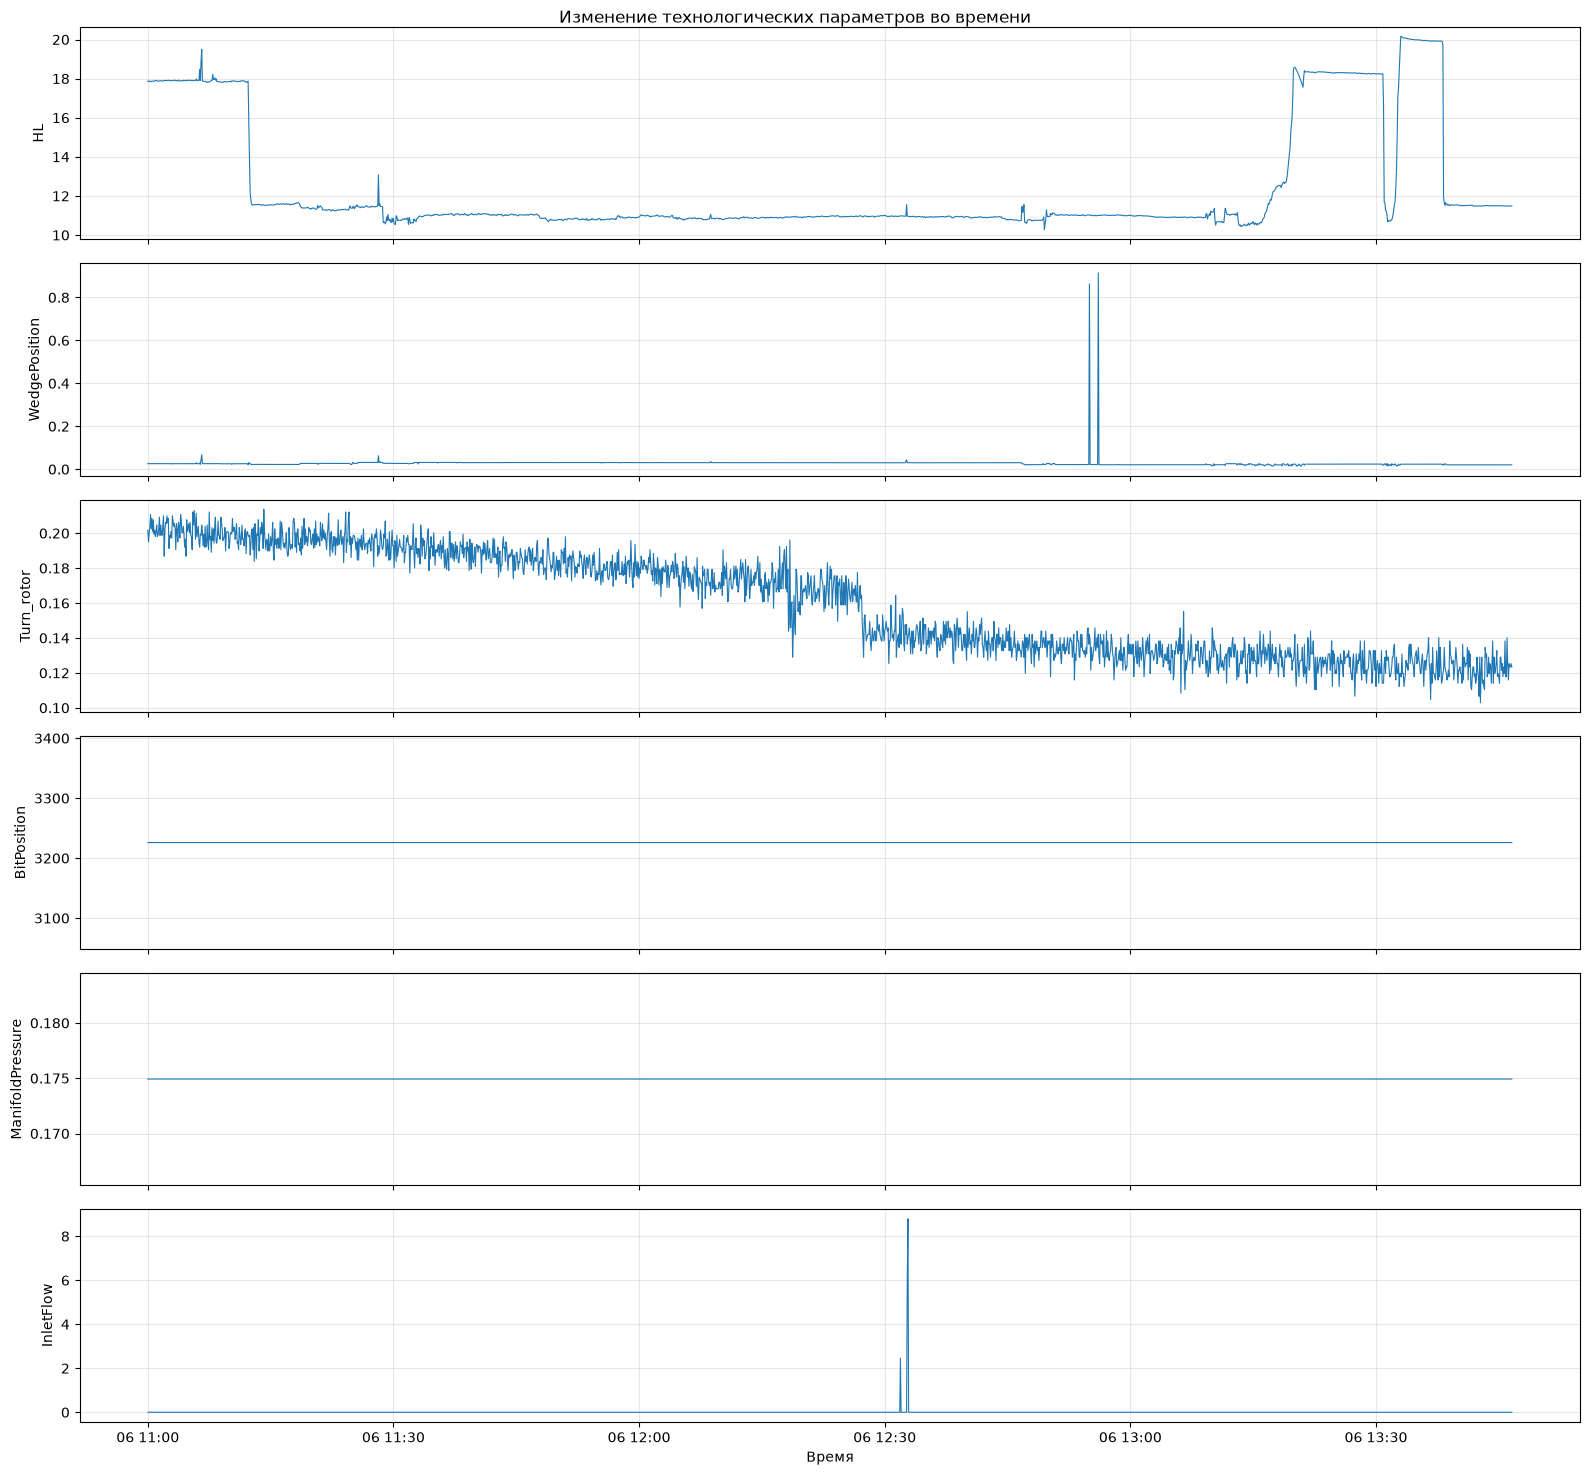

In [25]:
plot_df = df.iloc[:2000]

features = [
    "HL",
    "WedgePosition",
    "Turn_rotor",
    "BitPosition",
    "ManifoldPressure",
    "InletFlow"
]

fig, axes = plt.subplots(
    len(features),
    1,
    figsize=(16, 15),
    sharex=True
)

for ax, feature in zip(axes, features):
    ax.plot(plot_df["Time"], plot_df[feature], linewidth=0.8)
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Время")

plt.suptitle("Изменение технологических параметров во времени")
plt.tight_layout()
plt.show()

In [26]:
features_round = {
    "HL": 1,
    "WedgePosition": 1,
    "BitPosition": 0,
    "ManifoldPressure": 2,
    "Turn_rotor": 1
}

time_diff = df["Time"].diff().dt.total_seconds()
valid_intervals = time_diff.le(10)

for feature, decimals in features_round.items():
    states = df[feature].round(decimals)

    changes = (
        states.ne(states.shift(1))
        & valid_intervals
    )

    print(f"\n{feature}")
    print("Количество переключений:", changes.sum())
    print("Количество уникальных округлённых значений:", states.nunique())
    print("Наиболее частые значения:")
    display(states.value_counts().head(10))


HL
Количество переключений: 106737
Количество уникальных округлённых значений: 1041
Наиболее частые значения:


HL
 11.8    4279
 11.6    4249
 11.7    4012
-6.3     3552
 11.4    3550
 11.5    3383
 11.3    2991
 11.9    2763
 12.0    2707
 11.2    2160
Name: count, dtype: int64


WedgePosition
Количество переключений: 5449
Количество уникальных округлённых значений: 30
Наиболее частые значения:


WedgePosition
 1.0    93010
 0.0    57420
 1.1    14138
-0.6     7353
 1.2     4962
 1.8      807
 0.8      529
 0.4      500
 0.9      386
 0.7      343
Name: count, dtype: int64


BitPosition
Количество переключений: 17297
Количество уникальных округлённых значений: 3224
Наиболее частые значения:


BitPosition
0.0       20386
3226.0    12293
3227.0     5517
1.0        3962
13.0       3429
14.0       3306
10.0       3187
15.0       3158
16.0       3109
17.0       2990
Name: count, dtype: int64


ManifoldPressure
Количество переключений: 25775
Количество уникальных округлённых значений: 2057
Наиболее частые значения:


ManifoldPressure
0.25    41501
0.17    33193
0.22    11653
0.35     6005
0.36     3560
0.20     2711
0.44     1959
0.28     1539
0.34     1447
0.18     1349
Name: count, dtype: int64


Turn_rotor
Количество переключений: 50587
Количество уникальных округлённых значений: 719
Наиболее частые значения:


Turn_rotor
 0.2     47399
 0.1     32564
 0.3     27896
 0.4     13345
-39.4     3763
 0.0      1494
 42.9     1462
 39.1     1029
 43.1      841
 68.0      762
Name: count, dtype: int64

In [27]:
state = df["WedgePosition"].round(1)

# Новая группа при изменении состояния или большом разрыве во времени
new_group = (
    state.ne(state.shift(1))
    | time_diff.gt(10)
)

group_id = new_group.cumsum()

segments = pd.DataFrame({
    "State": state,
    "Time": df["Time"],
    "Group": group_id
})

# Объединяем последовательные наблюдения одного состояния
segments = (
    segments.groupby("Group")
    .agg(
        State=("State", "first"),
        Start=("Time", "min"),
        End=("Time", "max"),
        Count=("Time", "size")
    )
    .reset_index(drop=True)
)

segments["Duration_sec"] = (
    segments["End"] - segments["Start"]
).dt.total_seconds()

print("Количество временных сегментов:", len(segments))

print("\nСамые продолжительные состояния:")
display(
    segments.sort_values(
        "Duration_sec",
        ascending=False
    ).head(20)
)

print("\nСтатистика продолжительности по состояниям:")
display(
    segments.groupby("State")["Duration_sec"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("count", ascending=False)
    .head(15)
)

Количество временных сегментов: 5467

Самые продолжительные состояния:


,State,Start,End,Count,Duration_sec
11,0.0,2026-05-06 14:03:25,2026-05-07 00:29:50,7518,37585.0
2716,1.0,2026-05-10 07:21:10,2026-05-10 17:31:25,7324,36615.0
2727,1.0,2026-05-11 08:11:24,2026-05-11 14:36:45,14991,23121.0
4121,1.0,2026-05-14 13:47:20,2026-05-14 18:46:55,3596,17975.0
59,-0.6,2026-05-07 04:15:45,2026-05-07 08:05:05,2753,13760.0
3026,1.0,2026-05-12 07:20:50,2026-05-12 10:57:10,2597,12980.0
2978,-0.0,2026-05-11 23:38:40,2026-05-12 03:14:20,2589,12940.0
2650,1.0,2026-05-09 19:49:20,2026-05-09 23:06:55,2372,11855.0
2630,1.0,2026-05-09 12:14:00,2026-05-09 15:23:55,2280,11395.0
4241,1.0,2026-05-15 06:43:30,2026-05-15 09:41:45,2140,10695.0



Статистика продолжительности по состояниям:


,count,median,mean,max
State,,,,
1.0,1532,40.0,264.379243,36615.0
0.0,1153,105.0,243.204683,37585.0
1.1,1035,55.0,63.277295,340.0
1.2,489,45.0,45.721881,175.0
0.8,219,0.0,7.077626,530.0
0.4,206,0.0,7.135922,130.0
0.9,135,0.0,9.296296,130.0
0.3,121,0.0,5.206612,105.0
0.7,106,0.0,11.179245,305.0


In [28]:
state_analysis = df.copy()

state_analysis["WedgeState"] = (
    state_analysis["WedgePosition"].round(1)
)

result = (
    state_analysis.groupby("WedgeState")
    .agg(
        Count=("ID", "count"),
        HL_median=("HL", "median"),
        Turn_rotor_median=("Turn_rotor", "median"),
        BitPosition_median=("BitPosition", "median"),
        ManifoldPressure_median=("ManifoldPressure", "median"),
        InletFlow_median=("InletFlow", "median"),
        ROP_median=("ROP", "median"),
        Load_median=("Load", "median")
    )
    .sort_values("Count", ascending=False)
)

display(result.head(20))

,Count,HL_median,Turn_rotor_median,BitPosition_median,ManifoldPressure_median,InletFlow_median,ROP_median,Load_median
WedgeState,,,,,,,,
1.0,93010,63.398029,0.362102,19.056875,0.990969,0.000000,0.832193,0.774863
0.0,57420,11.771791,0.186919,1841.636963,0.220518,0.000000,0.832193,0.000000
1.1,14138,54.857294,12.121685,0.475781,14.423143,12.124956,5.110675,2.172862
-0.6,7353,10.381915,0.170025,3227.045166,0.174925,0.000000,0.371958,0.000000
1.2,4962,55.303036,13.958537,0.466289,14.497333,12.158113,5.285763,2.433809
1.8,807,59.044815,35.844116,5.845156,16.205359,13.781950,0.885209,0.622900
0.8,529,56.313564,0.156151,322.025330,0.246427,0.000000,0.832193,0.000000
0.4,500,13.896038,0.171889,3227.045166,0.174925,0.000000,0.371958,0.000000
0.9,386,69.424980,0.197997,22.590624,0.246427,0.000000,0.832193,0.309559


In [29]:
segment_data = df.copy()

segment_data["WedgeState"] = (
    segment_data["WedgePosition"].round(1)
)

segment_data["Group"] = group_id

segment_features = [
    "HL",
    "Turn_rotor",
    "BitPosition",
    "ManifoldPressure",
    "InletFlow",
    "ROP",
    "Load"
]

segment_summary = (
    segment_data.groupby("Group")
    .agg(
        WedgeState=("WedgeState", "first"),
        Start=("Time", "min"),
        End=("Time", "max"),
        Count=("ID", "count"),
        **{
            f"{feature}_median": (feature, "median")
            for feature in segment_features
        }
    )
    .reset_index()
)

segment_summary["Duration_sec"] = (
    segment_summary["End"] - segment_summary["Start"]
).dt.total_seconds()

# Оставляем сегменты продолжительностью не менее 30 секунд
long_segments = segment_summary[
    segment_summary["Duration_sec"] >= 30
]

display(
    long_segments.groupby("WedgeState")
    .agg(
        SegmentCount=("Group", "count"),
        MedianDuration=("Duration_sec", "median"),
        HL=("HL_median", "median"),
        Turn_rotor=("Turn_rotor_median", "median"),
        BitPosition=("BitPosition_median", "median"),
        ManifoldPressure=("ManifoldPressure_median", "median"),
        InletFlow=("InletFlow_median", "median"),
        ROP=("ROP_median", "median"),
        Load=("Load_median", "median")
    )
    .sort_values("SegmentCount", ascending=False)
    .head(15)
)

,SegmentCount,MedianDuration,HL,Turn_rotor,BitPosition,ManifoldPressure,InletFlow,ROP,Load
WedgeState,,,,,,,,,
1.0,1102,50.0,53.971450,0.231564,205.448395,0.336495,0.000000,0.832193,0.000000
0.0,1087,105.0,11.737765,0.201727,1289.605835,0.246427,0.000000,0.832193,0.000000
1.1,953,60.0,55.243446,14.223342,0.475781,14.569971,12.158113,5.109450,2.190173
1.2,356,50.0,55.975059,13.936159,0.479062,13.909545,12.158113,4.232599,2.153282
-0.6,23,415.0,12.897442,0.168160,3227.045166,0.174925,0.000000,0.371958,0.000000
0.4,19,70.0,-6.332245,0.171889,3227.045166,0.174925,0.000000,0.371958,0.000000
0.9,16,72.5,74.201405,0.250212,16.052813,0.246427,0.000000,0.832193,0.309559
0.5,14,85.0,3.733037,0.179349,3226.000000,0.174925,0.000000,0.371958,0.000000
0.8,13,95.0,67.622932,0.319211,22.590624,0.246427,0.000000,0.832193,0.357652


In [30]:
main_states = [0.0, 1.0, 1.1, 1.2, -0.6]

daily_states = segment_summary[
    segment_summary["WedgeState"].isin(main_states)
].copy()

daily_states["Date"] = daily_states["Start"].dt.date

daily_table = (
    daily_states.groupby(["Date", "WedgeState"])
    .agg(
        SegmentCount=("Group", "count"),
        TotalDuration=("Duration_sec", "sum")
    )
    .reset_index()
)

display(
    daily_table.pivot(
        index="Date",
        columns="WedgeState",
        values="SegmentCount"
    ).fillna(0).astype(int)
)

WedgeState,-0.6,0.0,1.0,1.1,1.2
Date,,,,,
2026-05-06,0,7,1,0,0
2026-05-07,28,157,168,167,42
2026-05-08,0,16,331,673,345
2026-05-09,0,15,105,191,101
2026-05-10,0,8,14,1,1
2026-05-11,0,85,68,0,0
2026-05-12,0,66,55,0,0
2026-05-13,0,273,266,0,0
2026-05-14,0,79,78,0,0


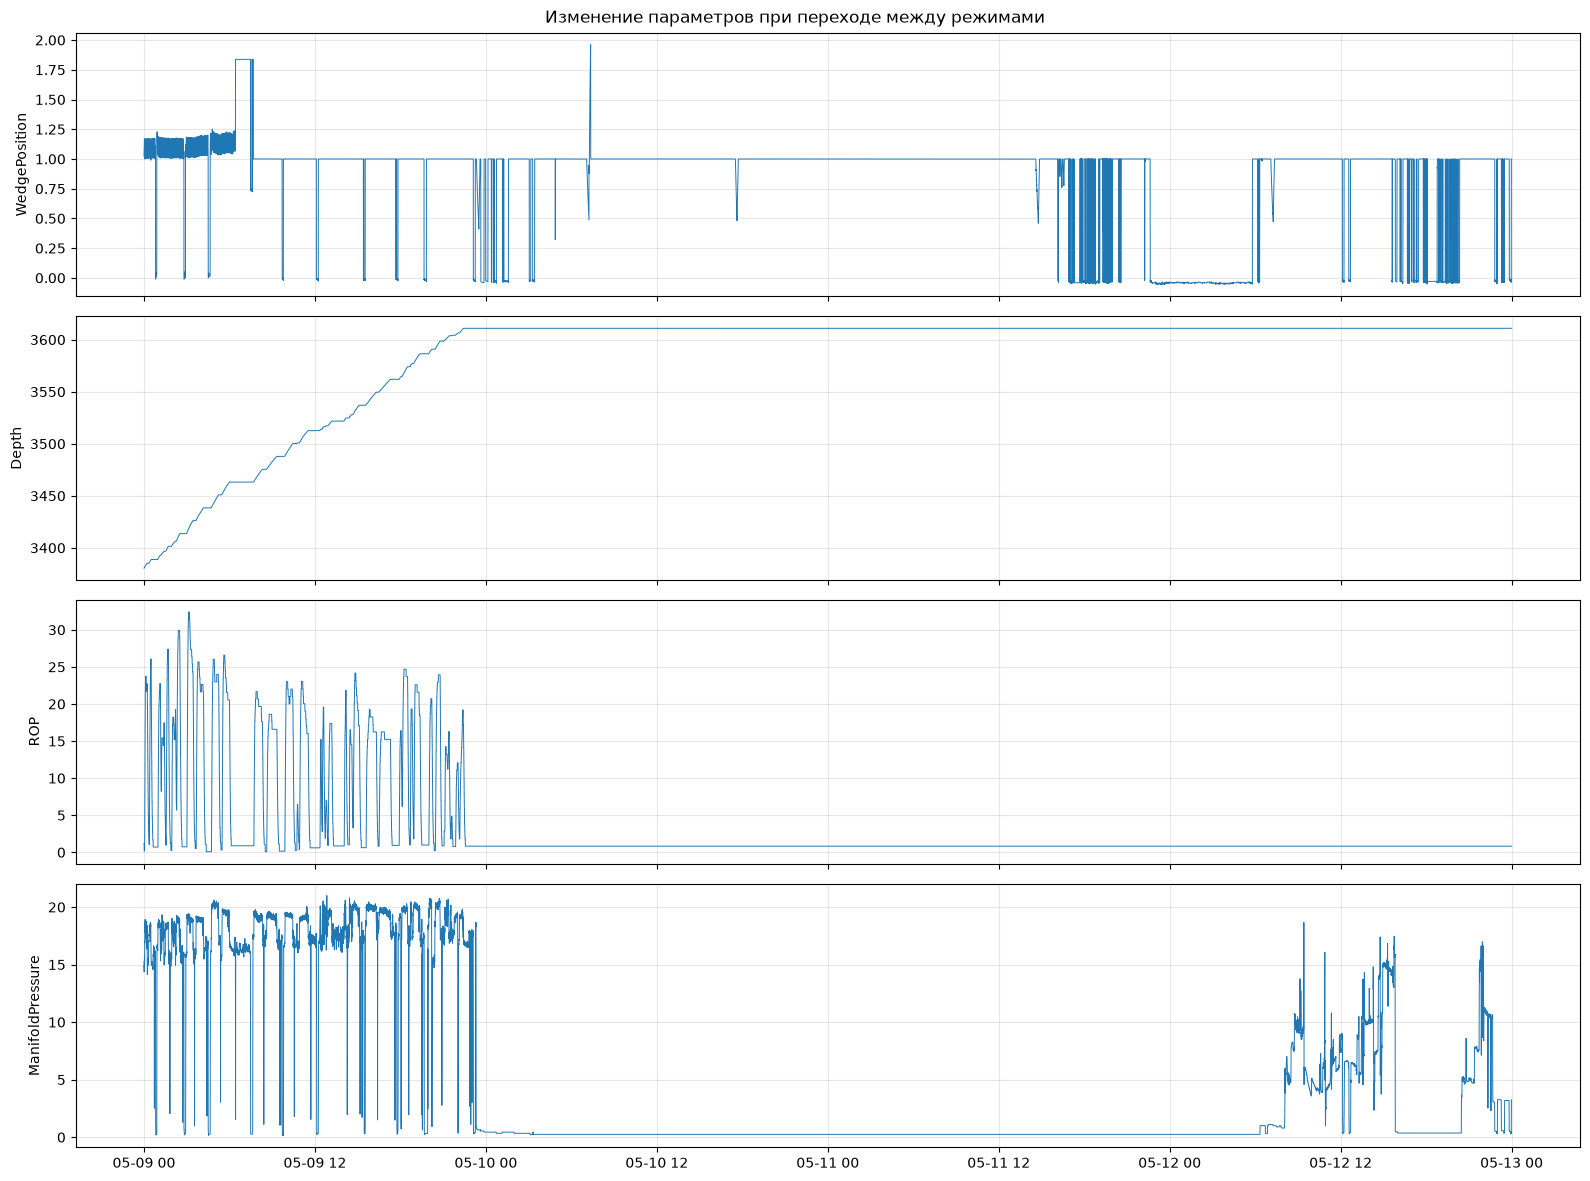

In [31]:
transition_df = df[
    (df["Time"] >= "2026-05-09") &
    (df["Time"] < "2026-05-13")
].copy()

features = [
    "WedgePosition",
    "Depth",
    "ROP",
    "ManifoldPressure"
]

fig, axes = plt.subplots(
    len(features), 1,
    figsize=(16, 12),
    sharex=True
)

for ax, feature in zip(axes, features):
    ax.plot(
        transition_df["Time"],
        transition_df[feature],
        linewidth=0.7
    )
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

plt.suptitle("Изменение параметров при переходе между режимами")
plt.tight_layout()
plt.show()

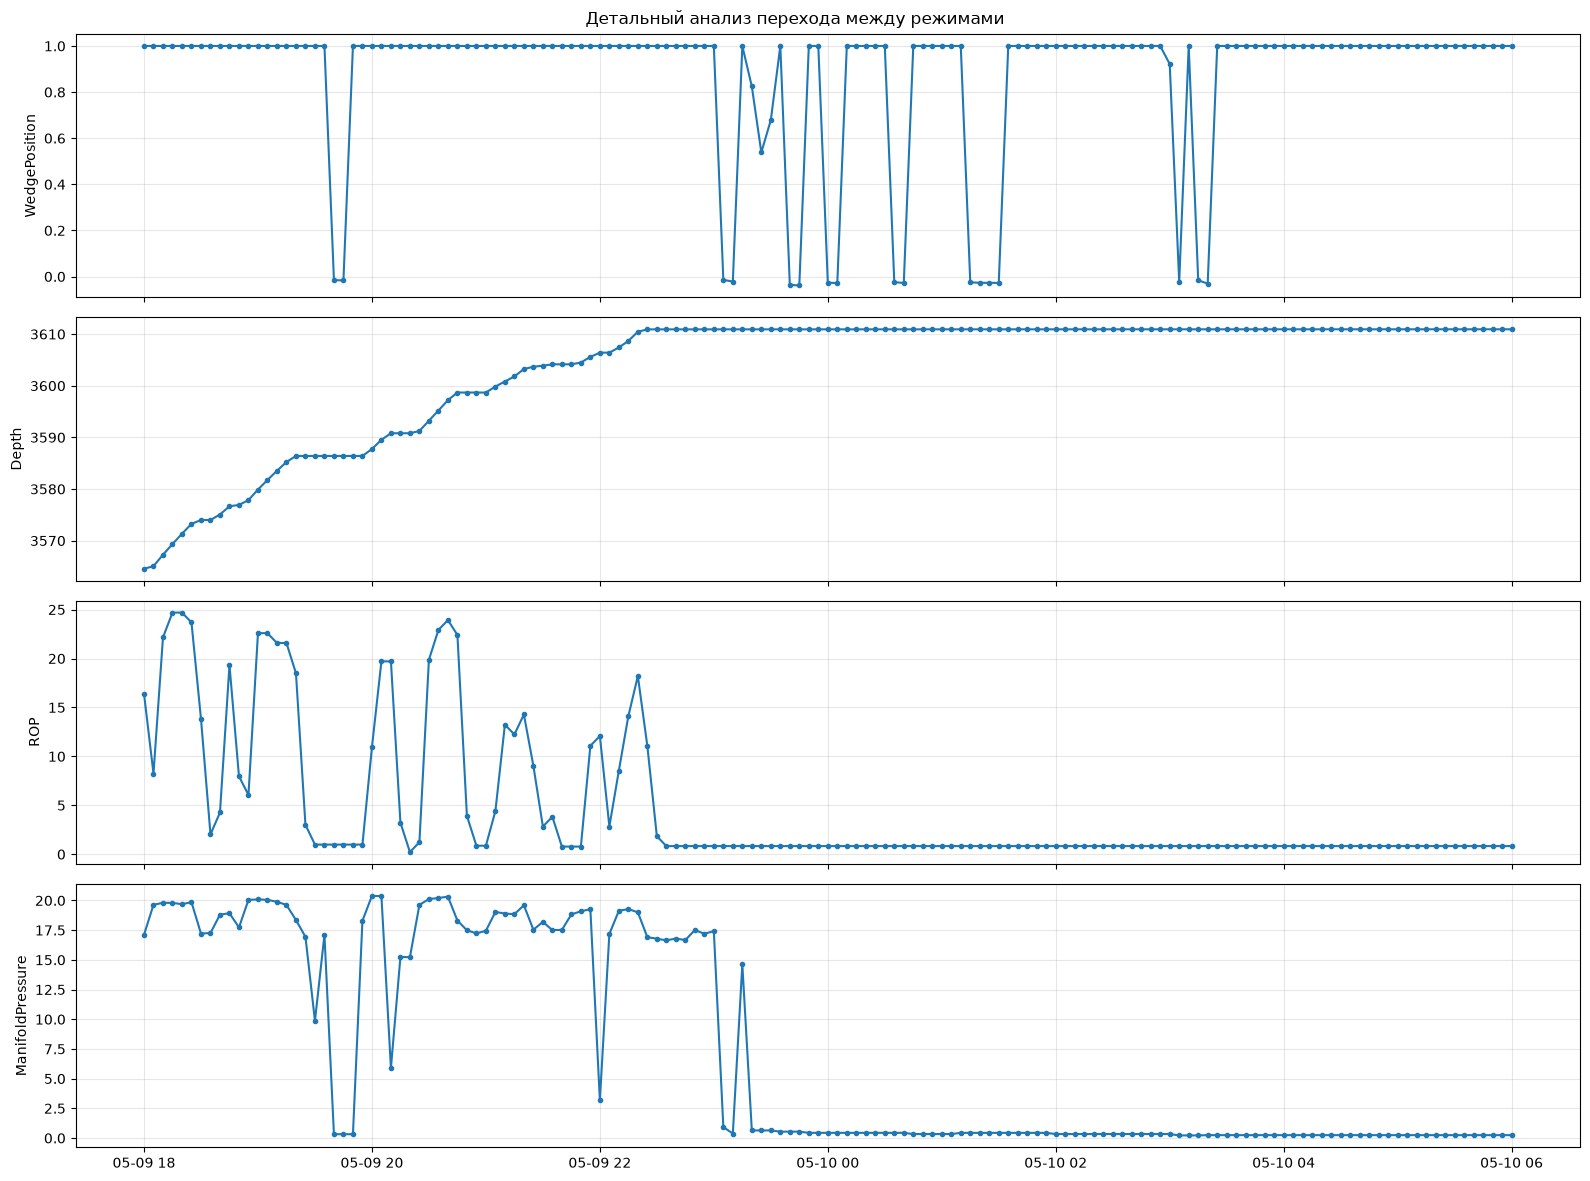

In [32]:
transition_zoom = df[
    (df["Time"] >= "2026-05-09 18:00:00") &
    (df["Time"] <= "2026-05-10 06:00:00")
].copy()

zoom_features = [
    "WedgePosition",
    "Depth",
    "ROP",
    "ManifoldPressure"
]

zoom_data = (
    transition_zoom
    .set_index("Time")[zoom_features]
    .resample("5min")
    .median()
)

fig, axes = plt.subplots(
    4, 1,
    figsize=(16, 12),
    sharex=True
)

for ax, feature in zip(axes, zoom_features):
    ax.plot(zoom_data.index, zoom_data[feature], marker=".")
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

plt.suptitle("Детальный анализ перехода между режимами")
plt.tight_layout()
plt.show()

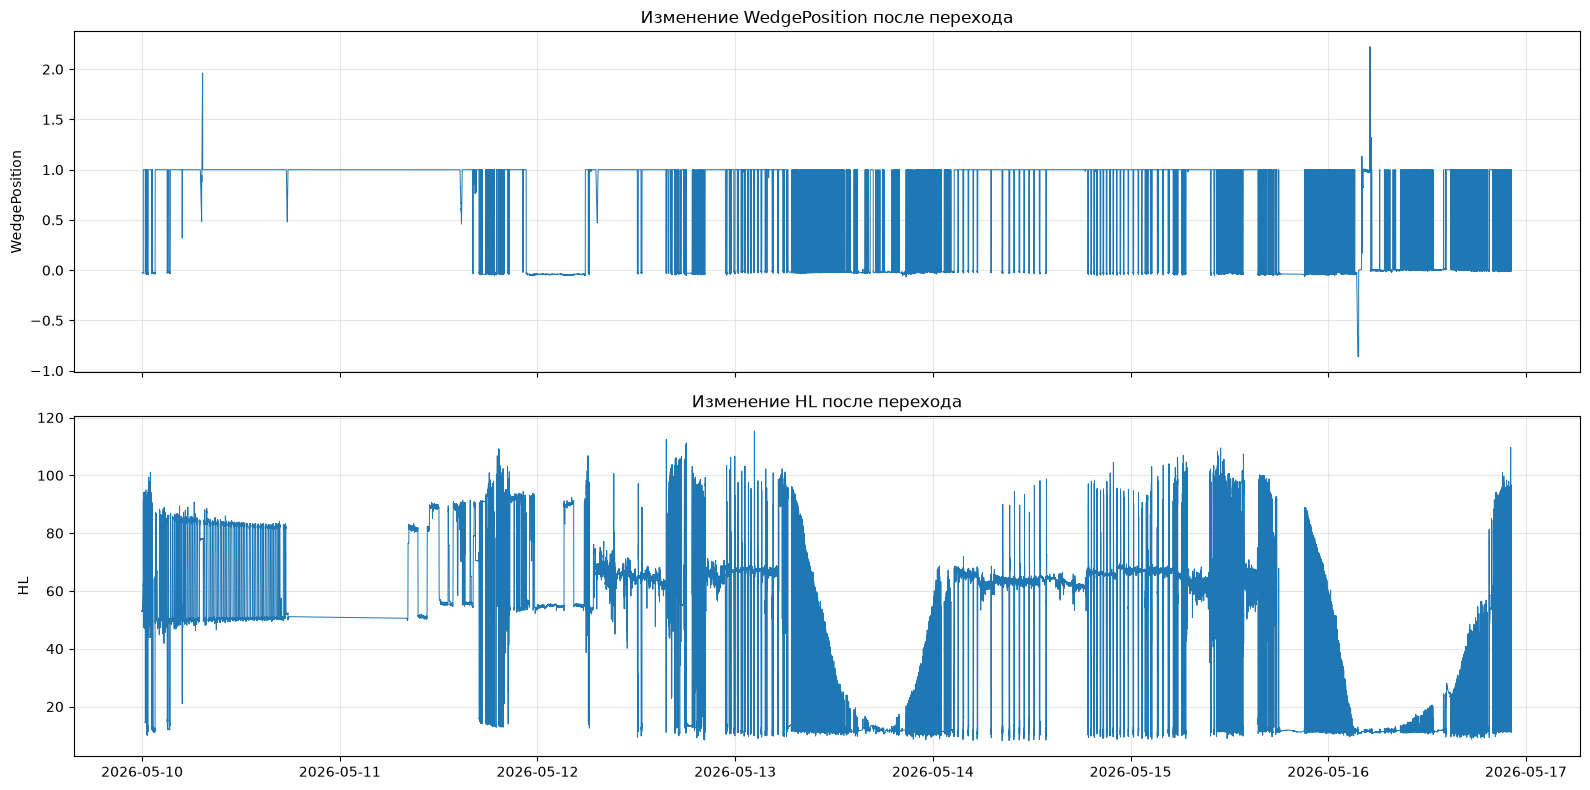

In [33]:
post_transition = df[
    (df["Time"] >= "2026-05-10") &
    (df["Time"] <= "2026-05-16 22:15:00")
].copy()

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 8),
    sharex=True
)

axes[0].plot(
    post_transition["Time"],
    post_transition["WedgePosition"],
    linewidth=0.7
)
axes[0].set_ylabel("WedgePosition")
axes[0].set_title("Изменение WedgePosition после перехода")
axes[0].grid(alpha=0.3)

axes[1].plot(
    post_transition["Time"],
    post_transition["HL"],
    linewidth=0.7
)
axes[1].set_ylabel("HL")
axes[1].set_title("Изменение HL после перехода")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
post_segments = segment_summary[
    segment_summary["Start"] >= "2026-05-10"
].copy()

post_segments["Date"] = post_segments["Start"].dt.date

daily_analysis = (
    post_segments.groupby(["Date", "WedgeState"])
    .agg(
        SegmentCount=("Group", "count"),
        MedianDuration=("Duration_sec", "median"),
        HL_median=("HL_median", "median")
    )
    .reset_index()
)

display(daily_analysis)

,Date,WedgeState,SegmentCount,MedianDuration,HL_median
0,2026-05-10,-0.0,8,235.0,13.225255
1,2026-05-10,0.2,1,0.0,47.983868
2,2026-05-10,0.3,2,0.0,49.541763
3,2026-05-10,0.4,2,0.0,53.159290
4,2026-05-10,0.5,2,95.0,65.016262
5,2026-05-10,0.6,3,80.0,52.170517
6,2026-05-10,0.7,3,70.0,52.147263
7,2026-05-10,0.8,9,0.0,52.144451
8,2026-05-10,0.9,4,70.0,64.997347
9,2026-05-10,1.0,14,475.0,52.426046


In [35]:
stable_segments = segment_summary[
    (segment_summary["Duration_sec"] >= 30) &
    (segment_summary["WedgeState"].isin([0.0, 1.0]))
].copy()

daily_stable = (
    stable_segments
    .assign(Date=lambda x: x["Start"].dt.date)
    .groupby(["Date", "WedgeState"])
    .agg(
        SegmentCount=("Group", "count"),
        MedianDuration=("Duration_sec", "median"),
        HL_median=("HL_median", "median"),
        Turn_rotor=("Turn_rotor_median", "median"),
        BitPosition=("BitPosition_median", "median"),
        ManifoldPressure=("ManifoldPressure_median", "median")
    )
    .reset_index()
)

display(daily_stable)

,Date,WedgeState,SegmentCount,MedianDuration,HL_median,Turn_rotor,BitPosition,ManifoldPressure
0,2026-05-06,0.0,7,2345.0,11.055351,0.145782,3226.000000,0.174925
1,2026-05-07,0.0,144,95.0,11.398435,0.207321,1732.026978,0.351125
2,2026-05-07,1.0,82,45.0,33.829041,0.209186,1386.990112,0.351125
3,2026-05-08,0.0,16,314.5,25.136103,0.172822,0.420508,8.127066
4,2026-05-08,1.0,285,45.0,55.124773,14.215882,0.465078,14.435447
5,2026-05-09,0.0,12,392.5,11.786864,0.188673,0.517383,0.313804
6,2026-05-09,1.0,74,50.0,55.450594,41.946754,0.340859,17.771521
7,2026-05-10,0.0,8,235.0,13.225255,0.196132,9.835762,0.438132
8,2026-05-10,1.0,11,865.0,54.015747,0.196132,14.365078,0.337894
9,2026-05-11,0.0,68,75.0,14.655929,0.332264,59.972479,0.246427
